# Stage 5 — explainability and efficiency

**Runtime → Change runtime type → T4 GPU → Save. Then Runtime → Run all.**

About **40 minutes**, mostly unattended.

---

### What this stage is for

The rest of the project has shown that *removing* the RR timing features destroys
Class S performance. That is evidence about the feature set. It is not evidence
that the trained model actually **uses** them — a model can be helped by a
feature at training time and lean on something else at prediction time.

This stage asks the model directly. It blanks out one region of the heartbeat at
a time — the P wave, the QRS complex, the T wave, or the four timing features —
and measures how much the model's confidence in the right answer falls. A big
fall means it was relying on that region.

Then it checks whether that story is trustworthy, by deleting regions in the
order the attribution claims matter most and seeing whether the model degrades
faster than if the regions were deleted at random. If it does not, the
attribution is decoration and we say so.

Finally it measures parameters, model size and per-beat latency.

### Two things to know before you start

**DS2 is never opened.** This stage works entirely inside DS1, and on beats each
model did not train on. Nothing here can affect the Stage 4 result.

**You can run it as many times as you like.** Unlike Stage 4, there is no
one-shot rule here. If something looks wrong, re-run it.

## 1. Confirm a GPU was allocated

In [1]:
import torch

assert torch.cuda.is_available(), (
    'No GPU. Runtime -> Change runtime type -> T4 GPU, then Run all again.')

print('GPU   :', torch.cuda.get_device_name(0))
print('torch :', torch.__version__)

GPU   : Tesla T4
torch : 2.11.0+cu130


## 2. Get the code

Public repository — nothing to request, nothing to upload.

In [2]:
%cd /content
!rm -rf ecg-paper
!git clone --depth 1 https://github.com/Rishabhhcodes/ecg-paper.git
%cd /content/ecg-paper

!pip install -q wfdb xgboost imbalanced-learn matplotlib

import subprocess
print('\ncommit :', subprocess.run(['git', 'rev-parse', '--short', 'HEAD'],
                                    capture_output=True, text=True).stdout.strip())

import os
assert os.path.exists('src/stage5_explain.py'), (
    'src/stage5_explain.py is not in the repository yet. Tell Rishabh — the '
    'notebook clones main, so the script has to be merged first.')
print('stage5_explain.py present')

/content
Cloning into 'ecg-paper'...
remote: Enumerating objects: 42, done.
remote: Counting objects: 100% (42/42), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 42 (delta 3), reused 32 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (42/42), 124.03 KiB | 4.77 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/ecg-paper

commit : 3856835
stage5_explain.py present


## 3. The dataset

You need `artifacts/ds1.npz`. There are two ways to get it; **use whichever
Rishabh told you**.

**A — he sent you the file.** Run the cell below and upload `ds1.npz`
(about 12 MB). This is the faster path and it uses the exact dataset every
earlier stage used.

**B — build it yourself.** Skip the upload cell and run the build cell instead.
It downloads ~90 MB from PhysioNet, which is sometimes slow and sometimes drops
the connection; the script retries on its own.

In [6]:
# --- A: upload ds1.npz -------------------------------------------------
import glob, os, shutil
import numpy as np
from google.colab import files

os.makedirs('artifacts', exist_ok=True)
files.upload()                      # pick ds1.npz

# An .npz IS a zip file. Move it; never unpack it, or the arrays scatter
# into the working directory and the file itself disappears.
for name in glob.glob('*.npz'):
    shutil.move(name, os.path.join('artifacts', os.path.basename(name)))

p = 'artifacts/ds1.npz'
assert os.path.exists(p), 'ds1.npz missing — re-run this cell and pick the file'
d = np.load(p)
assert sorted(d.files) == ['X', 'pid', 'rr', 'y'], sorted(d.files)
assert len(d['y']) == 50977, f"{len(d['y']):,} beats, expected 50,977"
print(f"ds1.npz  {os.path.getsize(p)/1e6:.1f} MB  {len(d['y']):,} beats  OK")

ds1.npz  12.3 MB  50,977 beats  OK


In [5]:
import os, shutil
os.makedirs('artifacts', exist_ok=True)
shutil.move('ds1.npz.zip', 'artifacts/ds1.npz')

import numpy as np
d = np.load('artifacts/ds1.npz')
print(sorted(d.files), len(d['y']))

['X', 'pid', 'rr', 'y'] 50977


In [ ]:
!cat src/download.py

"""
Box 1 — fetch the raw MIT-BIH Arrhythmia Database from PhysioNet.

Downloads only the 44 non-paced records the protocol uses.
Roughly 90 MB. Run once; it is cached on disk afterwards.
"""
import os
import sys

import wfdb

sys.path.insert(0, os.path.dirname(__file__))
from config import ALL_RECORDS, PACED_RECORDS, RAW_DIR


def download(out_dir=RAW_DIR, include_paced=False):
    """Download MIT-BIH records.

    include_paced=True also fetches 102/104/107/217. They are never used
    for training, but having them locally lets us show in the paper that
    the exclusion was deliberate rather than accidental.
    """
    os.makedirs(out_dir, exist_ok=True)

    records = [str(r) for r in ALL_RECORDS]
    if include_paced:
        records += [str(r) for r in PACED_RECORDS]

    print(f'Downloading {len(records)} records to {out_dir}/ ...')
    wfdb.dl_database('mitdb', dl_dir=out_dir, records=records)

    missing = [r for r in records
               if not os.path.exists(os.path.join

In [ ]:
!python -u src/download.py

Generating record list for: 100
Generating record list for: 101
Generating record list for: 103
Generating record list for: 105
Generating record list for: 106
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generating record list for: 210
Generating record list for: 212
Generating record list for: 213
Generati

In [ ]:
!python -u src/build_dataset.py


DS1 (training) — 22 records
  DS1 101:   1863 beats  {'N': 1858, 'S': 3, 'Q': 2}
  DS1 106:   2025 beats  {'N': 1505, 'V': 520}
  DS1 108:   1761 beats  {'N': 1738, 'S': 4, 'V': 17, 'F': 2}
  DS1 109:   2530 beats  {'N': 2490, 'V': 38, 'F': 2}
  DS1 112:   2537 beats  {'N': 2535, 'S': 2}
  DS1 114:   1877 beats  {'N': 1818, 'S': 12, 'V': 43, 'F': 4}
  DS1 115:   1951 beats  {'N': 1951}
  DS1 116:   2410 beats  {'N': 2300, 'S': 1, 'V': 109}
  DS1 118:   2276 beats  {'N': 2164, 'S': 96, 'V': 16}
  DS1 119:   1985 beats  {'N': 1541, 'V': 444}
  DS1 122:   2474 beats  {'N': 2474}
  DS1 124:   1617 beats  {'N': 1534, 'S': 31, 'V': 47, 'F': 5}
  DS1 201:   1961 beats  {'N': 1633, 'S': 128, 'V': 198, 'F': 2}
  DS1 203:   2978 beats  {'N': 2527, 'S': 2, 'V': 444, 'F': 1, 'Q': 4}
  DS1 205:   2654 beats  {'N': 2569, 'S': 3, 'V': 71, 'F': 11}
  DS1 207:   1858 beats  {'N': 1542, 'S': 106, 'V': 210}
  DS1 208:   2953 beats  {'N': 1585, 'S': 2, 'V': 992, 'F': 372, 'Q': 2}
  DS1 209:   3003 beats 

In [ ]:
import numpy as np
d = np.load('artifacts/ds1.npz')
print(sorted(d.files), len(d['y']))

['X', 'pid', 'rr', 'y'] 50977


In [ ]:
!cat src/build_dataset.py

"""
Box 7 — assemble DS1 / DS2 and write them to disk.

Output (artifacts/):
    ds1.npz, ds2.npz   X (n,216)  rr (n,4)  y (n,)  pid (n,)
    manifest.json      per-record counts, class distribution, config echo

The DS1/DS2 division is by record, so no patient contributes beats to
both. Everything downstream reads only these two files.
"""
import json
import os
import sys
import time

import numpy as np

sys.path.insert(0, os.path.dirname(__file__))
import config as C
from preprocess import segment_record


def build_split(record_ids, raw_dir, name):
    Xs, Rs, Ys, Ps, metas = [], [], [], [], []

    for rid in record_ids:
        t0 = time.time()
        beats, rr, y, pid, meta = segment_record(rid, raw_dir)
        Xs.append(beats); Rs.append(rr); Ys.append(y); Ps.append(pid)
        meta['seconds'] = round(time.time() - t0, 2)
        metas.append(meta)

        dist = {C.CLASS_NAMES[k]: int((y == k).sum()) for k in range(5)}
        dist = {k: v for k, v in dist.items() if v}
   

In [ ]:
!cat src/config.py

"""
Stage 1 configuration — inter-patient protocol constants.

Every number in this file traces to a citation. Do not change values
without updating the reference, because the protocol IS the contribution.
"""

# ----------------------------------------------------------------------
# Records
# ----------------------------------------------------------------------
# MIT-BIH Arrhythmia Database has 48 records from 47 subjects.
# ANSI/AAMI EC57 requires excluding records with paced beats.
PACED_RECORDS = [102, 104, 107, 217]

# De Chazal, O'Dwyer & Reilly (2004), IEEE TBME 51(7):1196-1206.
# DS1 = training, DS2 = test. No subject appears in both.
DS1 = [101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122, 124,
       201, 203, 205, 207, 208, 209, 215, 220, 223, 230]

DS2 = [100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212,
       213, 214, 219, 221, 222, 228, 231, 232, 233, 234]

ALL_RECORDS = sorted(DS1 + DS2)

# --------------------------------------------------------------

In [ ]:
# --- B: build it instead (skip if you used A) --------------------------
# !python src/download.py
# !python src/build_dataset.py
# !python src/verify_dataset.py

In [ ]:
%cd /content/ecg-paper
!pwd
!ls
!ls artifacts

/content/ecg-paper
/content/ecg-paper
artifacts	 docs		     make_stage4_zip.py  requirements.txt
CONTRIBUTING.md  fold_report.py      notebooks		 RUNBOOK.md
cv_compare.py	 make_stage3_zip.py  README.md		 src


## 4. The run — about 35 minutes

Three seeds × five folds. Each model trains on four folds of DS1 and is
explained on the fifth, which it never saw.

`-u` is load-bearing: without it Python buffers its output and this cell shows
nothing at all until the very end.

In [7]:
!python -u src/stage5_explain.py --strategy class_weight --seeds 0 1 2

STAGE 5 — EXPLAINABILITY AND EFFICIENCY   (cnn / class_weight / rr)
DS1 50,977 beats / 22 patients   device cuda
units: ['P', 'QRS', 'T', 'RR']   P(0, 54)  QRS(54, 108)  T(108, 216)
DS2 is not opened by this stage.

  seed 0 fold 0  top unit  N:T  S:RR  V:QRS  F:QRS              [54s]
  seed 0 fold 1  top unit  N:RR  S:RR  V:QRS                    [45s]
  seed 0 fold 2  top unit  N:T  S:RR  V:QRS  F:QRS              [44s]
  seed 0 fold 3  top unit  N:T  S:RR  V:RR  F:P                 [46s]
  seed 0 fold 4  top unit  N:P  S:RR  V:QRS  F:QRS              [101s]
  seed 1 fold 0  top unit  N:P  S:RR  V:QRS  F:QRS              [45s]
  seed 1 fold 1  top unit  N:T  S:RR  V:QRS                     [45s]
  seed 1 fold 2  top unit  N:P  S:RR  V:QRS  F:QRS              [43s]
  seed 1 fold 3  top unit  N:T  S:RR  V:QRS  F:P                [45s]
  seed 1 fold 4  top unit  N:T  S:RR  V:QRS  F:QRS              [46s]
  seed 2 fold 0  top unit  N:T  S:RR  V:RR  F:QRS               [45s]
  seed 2 fold

## 5. Look at the figures

attribution.png


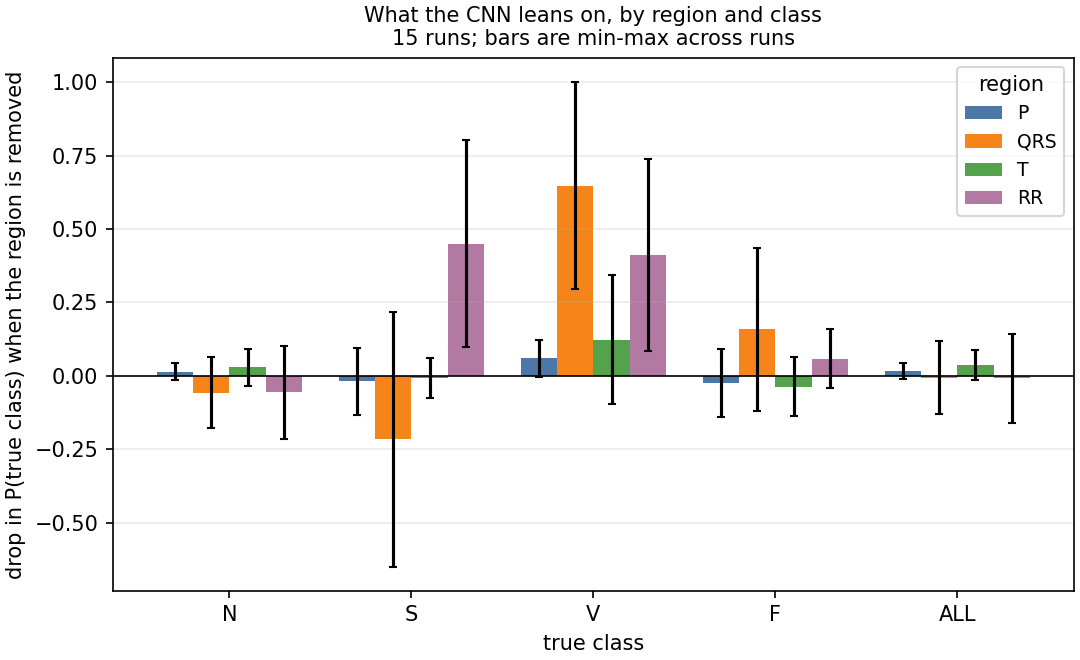

faithfulness.png


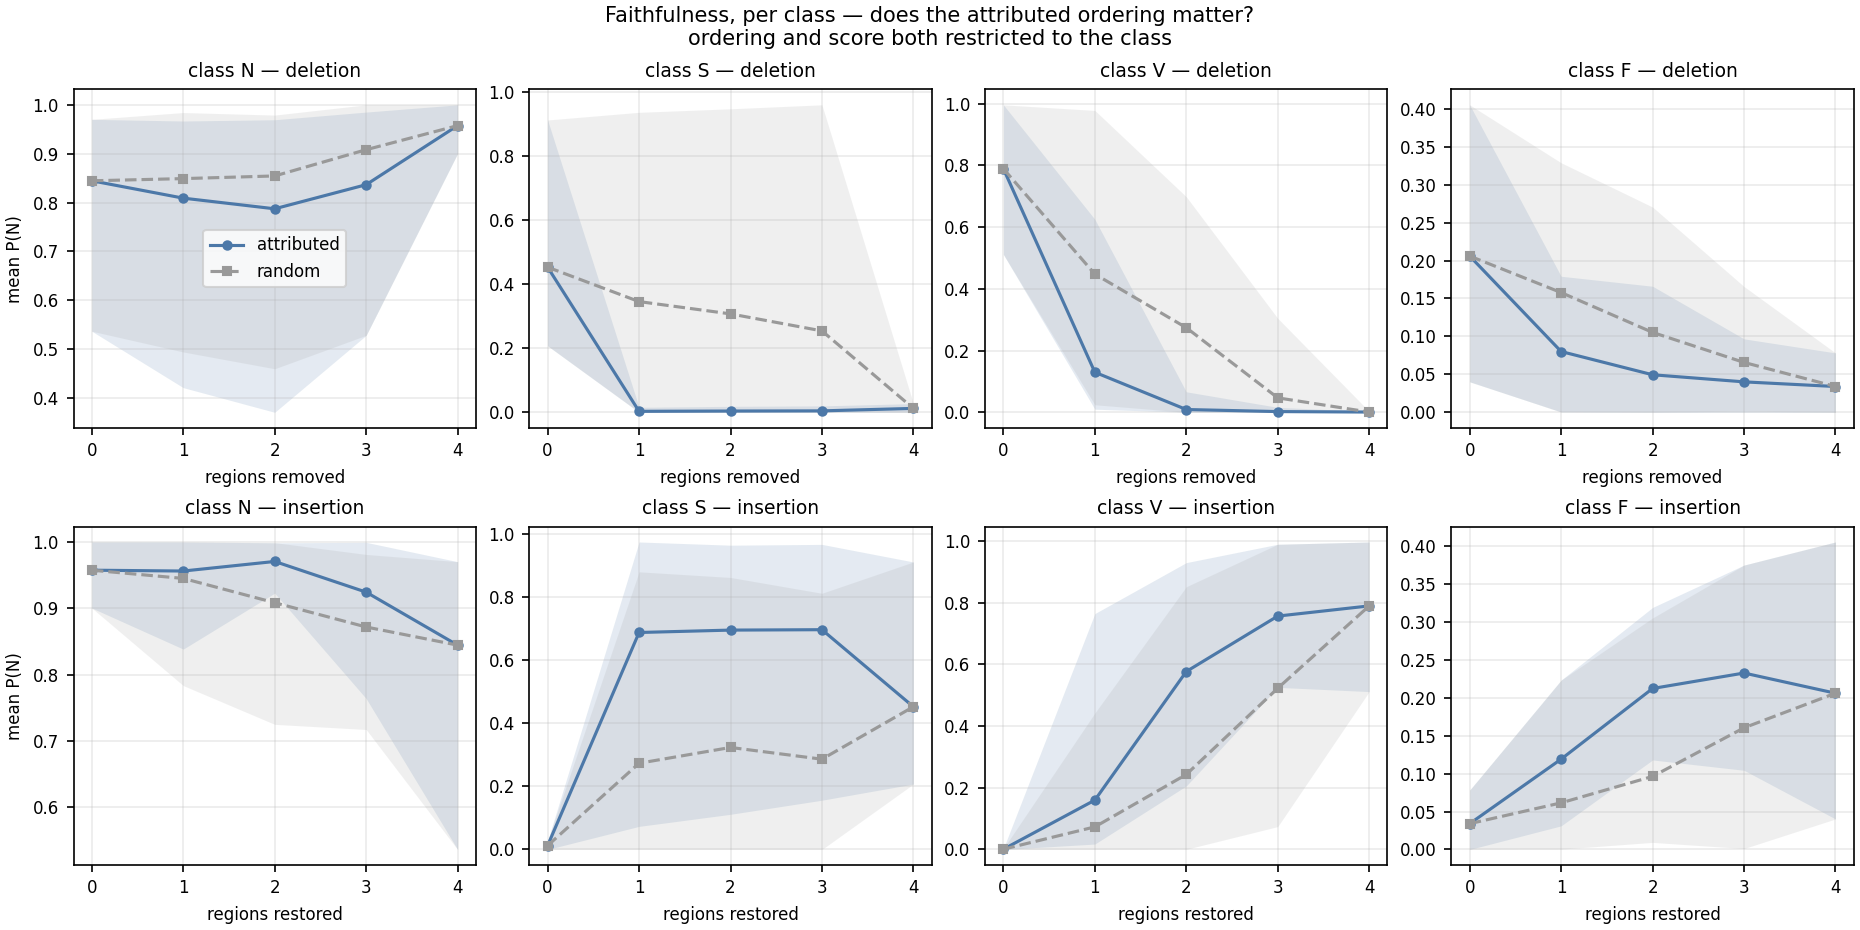

In [8]:
from IPython.display import Image, display

for f in ('attribution.png', 'faithfulness.png'):
    print(f)
    display(Image(f'artifacts/stage5/{f}'))

## 6. Package and download

In [9]:
import os
import zipfile

from google.colab import files

NEED = ['stage5_results.json', 'attribution.png', 'faithfulness.png']
missing = [f for f in NEED if not os.path.exists(f'artifacts/stage5/{f}')]
assert not missing, (
    f'cell 4 did not finish — {missing} were never written.\\n'
    'Scroll up, read the end of cell 4, and send that text.')

OUT = '/content/stage5_results.zip'
with zipfile.ZipFile(OUT, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in NEED:
        z.write(f'artifacts/stage5/{f}', f)

print('packed:', NEED)
files.download(OUT)

packed: ['stage5_results.json', 'attribution.png', 'faithfulness.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. What to send back, and what to read first

Send `stage5_results.zip` **and the full text output of cell 4**, as text rather
than a screenshot.

### Read these before you send

**The attribution table.** One row per heartbeat class, one column per region,
and a `*` marking the region the model leaned on most. The question the project
cares about: for class **S**, is `RR` the starred column? Class S is defined
clinically by a beat arriving early, so timing *should* dominate. If it does,
the attribution agrees with the ablation. If it does not, that is a genuine
finding and needs reporting, not hiding.

**The faithfulness lines.** Something like:

```
deletion  AUC  attributed 0.41   random 0.58   better in 15/15 runs
```

Attributed should be **lower** than random for deletion and **higher** for
insertion. If they come out level, the attribution is not informative and the
honest conclusion is that this method did not work on this model.

**Efficiency.** Parameter count around 146,000 and well under a millisecond per
beat. This is the embedded-feasibility claim.

### Stop and report, do not work around it

| Sign | What it means |
|---|---|
| `stage5_explain.py is not in the repository` | the script has not been merged yet |
| `folds.json is missing` | incomplete clone — pull main. **Do not run `make_folds.py`** |
| `AssertionError` about beat counts | wrong `ds1.npz` |
| every class starred on the same region | possible, but check the numbers are not all near zero first |
| all attributions ≈ 0 | the model is ignoring everything, which would mean something is wrong with how it was loaded |

There is no one-shot rule in this stage. Re-running costs nothing but time.